<a href="https://colab.research.google.com/github/SalmaAnindhia/PemMes_25_Salma/blob/main/JS08/JS08_Tugas1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
import scipy.cluster.hierarchy as sch
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score

In [ ]:
df = pd.read_csv('CC_Customer_Dataset.csv')
df.info()
df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 660 entries, 0 to 659
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Sl_No                660 non-null    int64
 1   Customer Key         660 non-null    int64
 2   Avg_Credit_Limit     660 non-null    int64
 3   Total_Credit_Cards   660 non-null    int64
 4   Total_visits_bank    660 non-null    int64
 5   Total_visits_online  660 non-null    int64
 6   Total_calls_made     660 non-null    int64
dtypes: int64(7)
memory usage: 36.2 KB


,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,1,87073,100000,2,1,1,0
1,2,38414,50000,3,0,10,9
2,3,17341,50000,7,1,3,4
3,4,40496,30000,5,1,1,4
4,5,47437,100000,6,0,12,3


In [ ]:
features = ['Avg_Credit_Limit', 'Total_Credit_Cards', 'Total_visits_bank',
            'Total_visits_online', 'Total_calls_made']

X = df[features].values
X_scaled = StandardScaler().fit_transform(X)

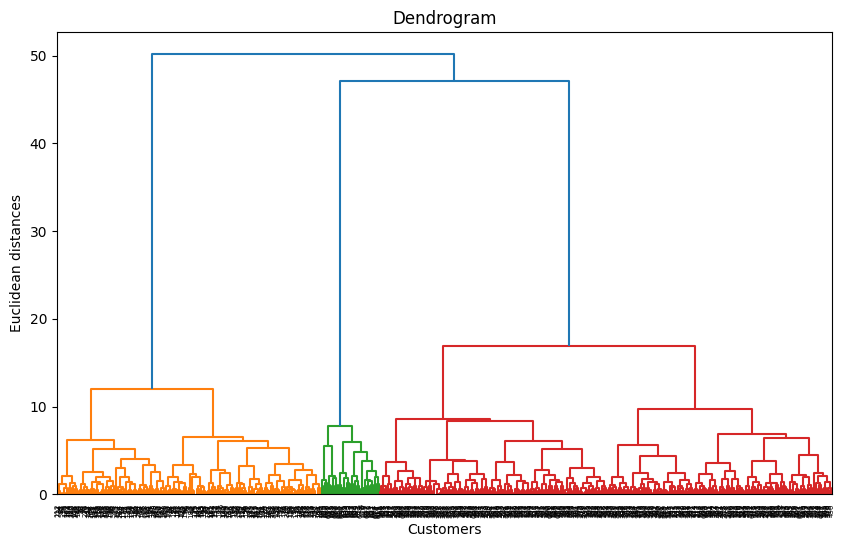

In [ ]:
plt.figure(figsize=(10, 6))
dendrogram = sch.dendrogram(sch.linkage(X_scaled, method='ward'))
plt.title('Dendrogram')
plt.xlabel('Customers')
plt.ylabel('Euclidean distances')
plt.show()

In [ ]:
hc = AgglomerativeClustering(n_clusters=3, metric='euclidean', linkage='ward')
y_hc = hc.fit_predict(X_scaled)

df['Cluster'] = y_hc
print(df['Cluster'].value_counts().sort_index())

Cluster
0    385
1    225
2     50
Name: count, dtype: int64


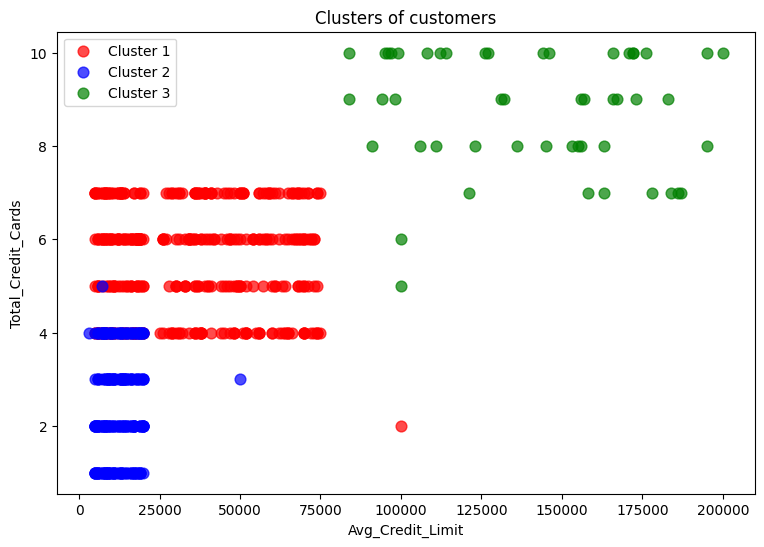

In [ ]:
colors = ['red', 'blue', 'green']

plt.figure(figsize=(9, 6))
for i in range(3):
    plt.scatter(df.loc[y_hc == i, 'Avg_Credit_Limit'],
                df.loc[y_hc == i, 'Total_Credit_Cards'],
                s=60, c=colors[i], label=f'Cluster {i+1}', alpha=0.7)
plt.title('Clusters of customers')
plt.xlabel('Avg_Credit_Limit')
plt.ylabel('Total_Credit_Cards')
plt.legend()
plt.show()

In [ ]:
sil = silhouette_score(X_scaled, y_hc)
dbi = davies_bouldin_score(X_scaled, y_hc)
print(f'Silhouette Coefficient : {sil}')
print(f'Davies-Bouldin Index   : {dbi}')

Silhouette Coefficient : 0.5147639589977819
Davies-Bouldin Index   : 0.680959518994733
